In [7]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


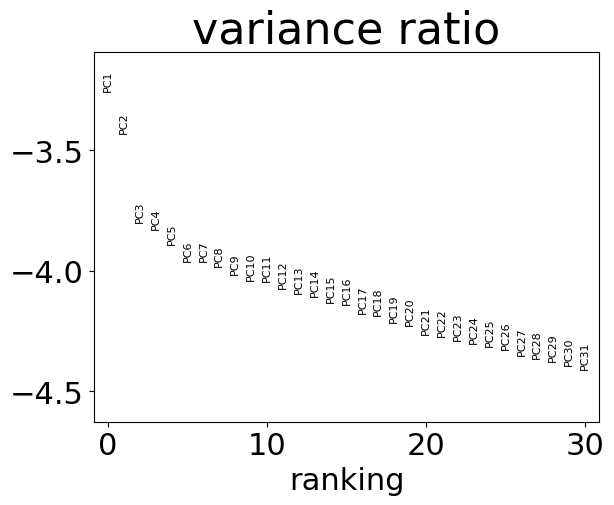

UMAP shape: (101, 3)


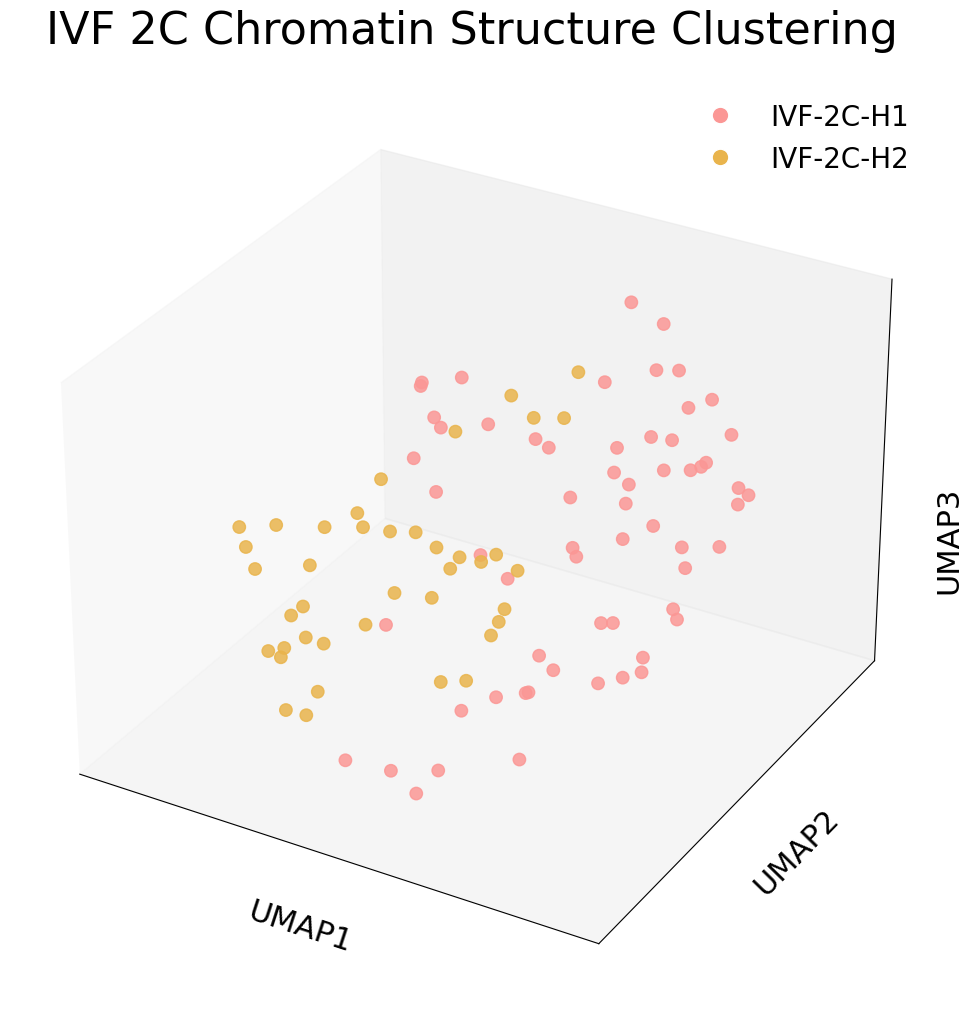

In [9]:
# =========================
# IVF 2C UMAP (optimized)
# =========================

import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 全局设置
# =========================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'

seed = 50
np.random.seed(seed)

# =========================
# 读取数据
# =========================
expression_matrix = pd.read_csv(
    "/home/lihaoxing/jupyter/IVF_2C_40k_1k_TADboundary_distribution.txt",
    sep="\t",
    index_col=0
).transpose()

adata = sc.AnnData(expression_matrix)

# =========================
# 标准化（关键！！）
# =========================
sc.pp.scale(adata, max_value=10)

# =========================
# PCA
# =========================
sc.tl.pca(adata, svd_solver='arpack', random_state=seed)

# 可视化 PCA variance（判断信号强度）
sc.pl.pca_variance_ratio(adata, log=True)

# =========================
# 构建邻接图（核心修正）
# =========================
sc.pp.neighbors(
    adata,
    n_neighbors=5,     # ↓ 更容易分群
    n_pcs=30,
    random_state=seed
)

# =========================
# UMAP
# =========================
sc.tl.umap(
    adata,
    n_components=3,
    min_dist=0.1,      # ↓ 更紧凑
    spread=1.5,
    random_state=seed
)

umap_result = adata.obsm['X_umap']
print("UMAP shape:", umap_result.shape)

# =========================
# Leiden clustering
# =========================
sc.tl.leiden(
    adata,
    resolution=0.5,   # ↑ 更容易拆开
    random_state=seed
)

clusters = adata.obs["leiden"]
cluster_sizes = clusters.value_counts()

# =========================
# 整理输出
# =========================
clusters_df = pd.DataFrame({
    "cell_id": clusters.index,
    "cluster_id": clusters.values
})

umap_df = pd.DataFrame(
    umap_result,
    columns=["UMAP_1", "UMAP_2", "UMAP_3"]
)

combined_df = pd.concat([clusters_df, umap_df], axis=1)

# 写文件
combined_df.to_csv(
    "IVF_2C_UMAP_optimized.txt",
    sep="\t",
    index=False
)

# =========================
# 颜色策略
# =========================
color_map = {
    cid: '#fb9795' if cluster_sizes[cid] > cluster_sizes.mean() else '#E9B44C'
    for cid in cluster_sizes.index
}

# =========================
# =========================
# 3D 可视化
# =========================
plt.rcParams.update({
    "font.size": 22,
    "axes.titlesize": 32,
    "axes.labelsize": 22,
    "legend.fontsize": 20
})

fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

# 先画点（不加label）
for cluster_id in combined_df["cluster_id"].unique():
    idx = combined_df["cluster_id"] == cluster_id

    ax.scatter(
        combined_df.loc[idx, "UMAP_1"],
        combined_df.loc[idx, "UMAP_2"],
        combined_df.loc[idx, "UMAP_3"],
        s=80,
        alpha=0.85,
        c=color_map[cluster_id]
    )

# =========================
# 手动构建 legend（核心）
# =========================
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], marker='o', color='w',
           label='IVF-2C-H1',
           markerfacecolor='#fb9795', markersize=12),

    Line2D([0], [0], marker='o', color='w',
           label='IVF-2C-H2',
           markerfacecolor='#E9B44C', markersize=12)
]

ax.legend(handles=legend_elements, frameon=False)

# =========================
# 其他保持不变
# =========================
ax.set_title("IVF 2C Chromatin Structure Clustering", pad=25)

ax.set_xlabel("UMAP1", labelpad=15)
ax.set_ylabel("UMAP2", labelpad=15)

ax.text2D(1, 0.5, "UMAP3",
          transform=ax.transAxes,
          rotation=90,
          va='center')

ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

plt.savefig(
    "IVF_2C_Chromatin_Structure-based_Clustering.svg",
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

plt.show()

/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


umap_result形状: (208, 3)
数据框形状: (208, 5)


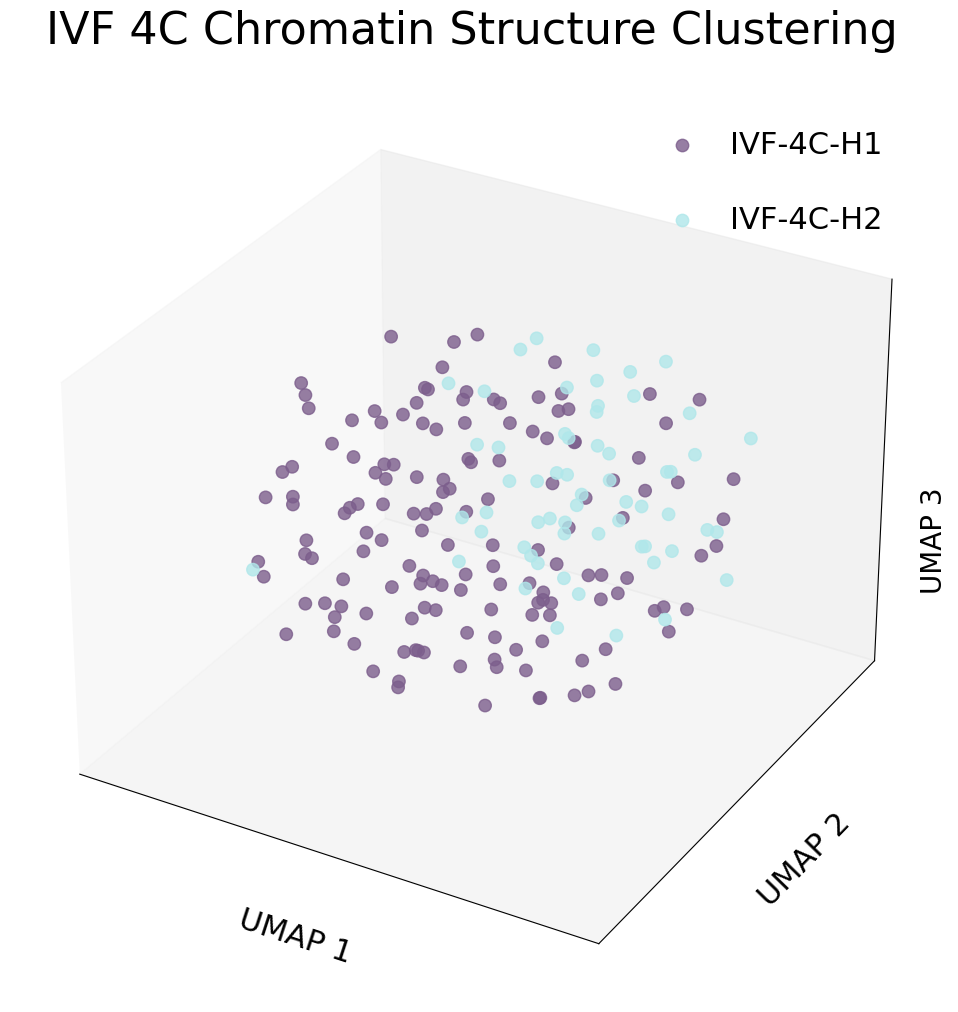

In [10]:
# IVF 4c UMAP 40k TAD boundary_1k_seed 0 10 20 30 60 99
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

# ===== 全局字体与样式设置（与雷达图统一） =====
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 22,          # 基础字体
    "axes.titlesize": 32,     # 标题
    "axes.labelsize": 22,     # 坐标轴标签
    "legend.fontsize": 22,    # 图例
    "xtick.labelsize": 22,
    "ytick.labelsize": 22
})

# ===== 设置随机种子 =====
seed = 0
np.random.seed(seed)

# ===== 读取数据 =====
expression_matrix = pd.read_csv(
    "/home/lihaoxing/jupyter/IVF_4C_40k_1k_TADboundary_distribution.txt",
    sep="\t", index_col=0
).transpose()

# ===== 创建 AnnData 并降维聚类 =====
adata = sc.AnnData(expression_matrix)
sc.tl.pca(adata, random_state=seed)
sc.pp.neighbors(adata, use_rep="X", random_state=seed)
sc.tl.umap(adata, n_components=3, random_state=seed)
umap_result = adata.obsm['X_umap']
print("umap_result形状:", umap_result.shape)

sc.tl.leiden(adata, flavor="igraph", resolution=0.845, random_state=seed)
clusters = adata.obs["leiden"]

# ===== 整理数据框 =====
clusters_df = pd.DataFrame({
    "cell_id": clusters.index,
    "cluster_id": clusters.values
})
umap_df = pd.DataFrame(umap_result, columns=["UMAP_1", "UMAP_2", "UMAP_3"])
combined_df = pd.concat([clusters_df, umap_df], axis=1)
print("数据框形状:", combined_df.shape)

# ===== 保存 UMAP 坐标与聚类 =====
combined_df.to_csv('IVF_4C_40k_TADboundary_1k_UMAP_seed0.txt', sep='\t', index=False)

# ===== 计算每个聚类的细胞数量（修复缺失变量） =====
cluster_sizes = combined_df['cluster_id'].value_counts()

# ===== 颜色映射：细胞多的为青色，少的为红色 =====
color_map = {
    cluster_id: '#7c5e8c' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '#b0e7ea'
    for cluster_id in cluster_sizes.index
}


# ===== 绘制三维散点图 =====
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

for cluster_id in combined_df["cluster_id"].unique():
    idx = combined_df[combined_df["cluster_id"] == cluster_id].index
    ax.scatter(
        combined_df.loc[idx, "UMAP_1"],
        combined_df.loc[idx, "UMAP_2"],
        combined_df.loc[idx, "UMAP_3"],
        label=f"IVF-4C-H{'1' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '2'}",
        alpha=0.8,
        s=80,
        c=color_map[cluster_id]
    )

# ===== 标题与坐标轴标签 =====
ax.set_title("IVF 4C Chromatin Structure Clustering", pad=25)
ax.set_xlabel("UMAP 1", labelpad=20)
ax.set_ylabel("UMAP 2", labelpad=20)
ax.set_zlabel("", labelpad=20)   # 留空，改用 text2D

# Z轴标签（右侧垂直，防止裁剪）
ax.text2D(
    1, 0.5, "UMAP 3",
    transform=ax.transAxes,
    fontsize=20,
    rotation=90,
    va='center',
    ha='center'
)

# 去掉刻度线
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# ===== 图例（无边框，间距舒适） =====
legend = ax.legend(
    loc='best',
    frameon=False,
    borderpad=1.2,
    labelspacing=1.5,
    handlelength=1.5
)

# ===== 保存高清 SVG =====
plt.savefig(
    'IVF_4C_Chromatin_Structure-based_Clustering.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)
plt.show()

/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
2026-06-25 14:22:02.605682: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-06-25 14:22:03.473473: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


umap_result形状: (106, 3)
clusters_df形状: (106, 2)
数据框形状: (106, 5)
     cell_id cluster_id    UMAP_1    UMAP_2     UMAP_3
0     2-10-1          0 -2.643259 -0.757259  10.092086
1    2-101-2          0 -2.796085 -0.284219   9.322929
2    2-104-2          0 -2.664969 -1.545387   9.682956
3    2-105-1          1 -2.111980  0.667635  10.658815
4    2-105-2          0 -1.077856 -0.016406   8.679852
..       ...        ...       ...       ...        ...
101  NPB-8-1          0 -1.662570 -1.928306  11.101103
102  PB-11-1          0 -2.468660 -2.123486   9.276681
103   PB-4-1          0 -0.358185  0.597917  10.430513
104   PB-7-2          1 -1.644352  1.380399   9.916547
105   PB-8-1          1 -3.461890 -0.890831   9.460978

[106 rows x 5 columns]


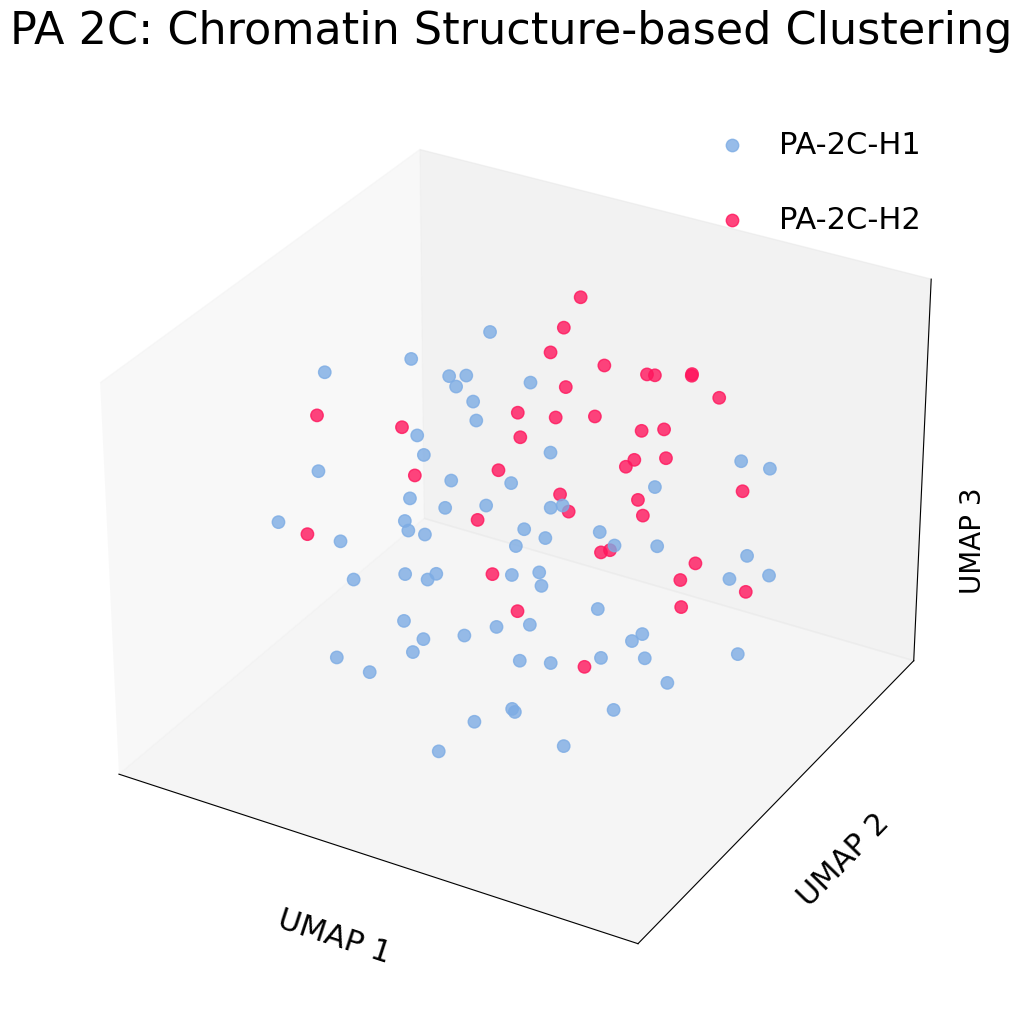

In [2]:
#PA 2c UMAP 40k TAD boundary_1k_seed 0 10 20 30 60 99
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import subprocess
import sys
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 设置随机种子
seed = 99
np.random.seed(seed)

# 读取表达量矩阵
expression_matrix = pd.read_csv("/home/lihaoxing/jupyter/PA_2C_40k_1k_TADboundary_distribution.txt", sep="\t", index_col=0).transpose()

# 创建 AnnData 对象
adata = sc.AnnData(expression_matrix)

# 主成分分析（PCA），并可视化 PCA 的方差比例
sc.tl.pca(adata, random_state=seed)

# 使用 PCA 结果计算细胞之间的近邻关系，使用原始数据进行邻域计算
sc.pp.neighbors(adata, use_rep="X", random_state=seed)

# 使用 UMAP 算法对数据进行降维
sc.tl.umap(adata, n_components=3, random_state=seed)
# 获取UMAP结果
umap_result = adata.obsm['X_umap']

# 打印UMAP结果的形状
print("umap_result形状:", umap_result.shape)

# 使用 Leiden 算法进行细胞聚类,通过调整resolution大小调整聚类数量多少
sc.tl.leiden(adata, flavor="igraph", resolution=0.895, random_state=seed)

# 获取聚类结果
clusters = adata.obs["leiden"]

# 构建包含细胞 ID 和对应聚类 ID 的列表
data = [(cell_id, cluster_id) for cell_id, cluster_id in clusters.items()]

# 转换为数据框
clusters_df = pd.DataFrame(data, columns=["cell_id", "cluster_id"])
print("clusters_df形状:", clusters_df.shape)

# 将UMAP结果转换为数据框，并设置列名为 'UMAP_1', 'UMAP_2' 和 'UMAP_3'
umap_df = pd.DataFrame(umap_result, columns=["UMAP_1", "UMAP_2", "UMAP_3"])

# 将聚类结果和UMAP结果左右拼接为一个新的数据框
combined_df = pd.concat([clusters_df, umap_df], axis=1)

# 打印新数据框的形状
print("数据框形状:", combined_df.shape)
print(combined_df)

with open('PA_2C_40k_TADboundary_1k_UMAP_seed99.txt', 'w') as file:
    # 遍历DataFrame的每一行
    for index, row in combined_df.iterrows():
        # 将每行内容转换为字符串
        line = '\t'.join([str(value) for value in row.values])
        # 写入文件
        file.write(line + '\n')
        
# 计算每个聚类的细胞数量
cluster_sizes = combined_df["cluster_id"].value_counts()

# 根据细胞数量分配颜色，细胞多的用红色，少的用蓝色
color_map = {cluster_id: '#7dace4' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '#ff165d' 
             for cluster_id in cluster_sizes.index}

# =========================
# 全局字体控制（关键）
# =========================
plt.rcParams.update({
    "font.size": 22,          # 基础字体
    "axes.titlesize": 32,     # 标题
    "axes.labelsize": 22,     # 坐标轴
    "legend.fontsize": 22,    # 图例
    "xtick.labelsize": 22,
    "ytick.labelsize": 22
})

# =========================
# 三维绘图
# =========================
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

for cluster_id in combined_df["cluster_id"].unique():
    cluster_indices = combined_df[combined_df["cluster_id"] == cluster_id].index

    ax.scatter(
        combined_df.loc[cluster_indices, "UMAP_1"],
        combined_df.loc[cluster_indices, "UMAP_2"],
        combined_df.loc[cluster_indices, "UMAP_3"],
        label=f"PA-2C-H{'1' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '2'}",
        alpha=0.8,
        s=80,   # 点更大
        c=color_map[cluster_id]
    )

# =========================
# 标题 & 坐标轴
# =========================
ax.set_title("PA 2C: Chromatin Structure-based Clustering", pad=25)

ax.set_xlabel("UMAP 1", labelpad=20)
ax.set_ylabel("UMAP 2", labelpad=20)
ax.set_zlabel("", labelpad=20)

# 替代Z轴标签（防裁剪）
# ✅ 用这个（永远不被裁剪）
ax.text2D(
    1, 0.5, "UMAP 3",
    transform=ax.transAxes,
    fontsize=20,
    rotation=90,
    va='center',
    ha='center'
)

# 去刻度
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# =========================
# 图例（重点放大）
# =========================
legend = plt.legend(
    loc='best',
    frameon=False,
    borderpad=1.2,
    labelspacing=1.5,
    handlelength=1.5
)

# =========================
# 保存（高清）
# =========================
plt.savefig(
    'PA_2C_Chromatin_Structure-based_Clustering.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

plt.show()

/home/lihaoxing/miniconda3/envs/jupyter/lib/python3.9/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


umap_result形状: (194, 3)
clusters_df形状: (194, 2)
数据框形状: (194, 5)
     cell_id cluster_id     UMAP_1    UMAP_2    UMAP_3
0    4-100-1          0   8.227152  6.478743  3.171328
1    4-100-2          0   9.835279  6.161525  2.003853
2    4-100-3          1   9.714829  6.346812  3.976260
3    4-104-3          0   9.439295  5.635978  2.754509
4      4-1-1          0  10.779097  5.820198  2.197036
..       ...        ...        ...       ...       ...
189   Y4-4-1          1  11.609145  7.256082  2.562579
190   Y4-4-2          0   7.717615  5.757544  2.437721
191   Y4-7-2          0   8.281442  5.507424  2.370531
192   Y4-7-3          0   8.089021  5.199238  3.008157
193   Y4-7-4          1   9.527551  4.603210  1.269913

[194 rows x 5 columns]


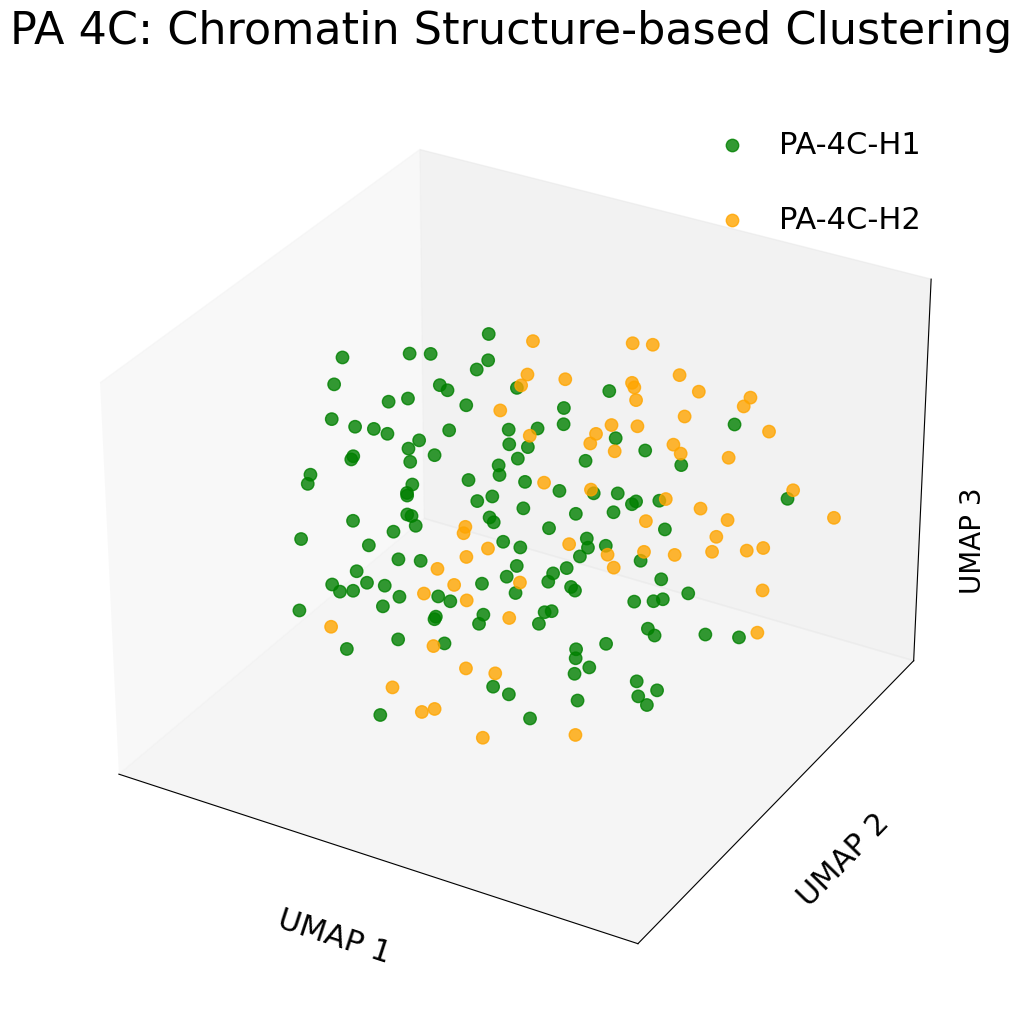

In [3]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 设置随机种子
seed = 0
np.random.seed(seed)

# 读取表达量矩阵
expression_matrix = pd.read_csv("/home/lihaoxing/jupyter/PA_4C_40k_1k_TADboundary_distribution.txt", sep="\t", index_col=0).transpose()

# 创建 AnnData 对象
adata = sc.AnnData(expression_matrix)

# 主成分分析（PCA），并可视化 PCA 的方差比例
sc.tl.pca(adata, random_state=seed)

# 使用 PCA 结果计算细胞之间的近邻关系，使用原始数据进行邻域计算
sc.pp.neighbors(adata, use_rep="X", random_state=seed)

# 使用 UMAP 算法对数据进行降维
sc.tl.umap(adata, n_components=3, random_state=seed)
# 获取UMAP结果
umap_result = adata.obsm['X_umap']

# 打印UMAP结果的形状
print("umap_result形状:", umap_result.shape)

# 使用 Leiden 算法进行细胞聚类
sc.tl.leiden(adata, flavor="igraph", resolution=0.835, random_state=seed)

# 获取聚类结果
clusters = adata.obs["leiden"]

# 构建包含细胞 ID 和对应聚类 ID 的列表
data = [(cell_id, cluster_id) for cell_id, cluster_id in clusters.items()]

# 转换为数据框
clusters_df = pd.DataFrame(data, columns=["cell_id", "cluster_id"])
print("clusters_df形状:", clusters_df.shape)

# 将UMAP结果转换为数据框，并设置列名为 'UMAP_1', 'UMAP_2' 和 'UMAP_3'
umap_df = pd.DataFrame(umap_result, columns=["UMAP_1", "UMAP_2", "UMAP_3"])

# 将聚类结果和UMAP结果左右拼接为一个新的数据框
combined_df = pd.concat([clusters_df, umap_df], axis=1)

# 打印新数据框的形状
print("数据框形状:", combined_df.shape)
print(combined_df)

with open('PA_4C_40k_TADboundary_1k_UMAP_seed0.txt', 'w') as file:
    # 遍历DataFrame的每一行
    for index, row in combined_df.iterrows():
        # 将每行内容转换为字符串
        line = '\t'.join([str(value) for value in row.values])
        # 写入文件
        file.write(line + '\n')

# 计算每个聚类的细胞数量
cluster_sizes = combined_df["cluster_id"].value_counts()

# 根据细胞数量分配颜色，细胞多的用红色，少的用蓝色
color_map = {cluster_id: 'green' if cluster_sizes[cluster_id] > cluster_sizes.mean() else 'orange' 
             for cluster_id in cluster_sizes.index}

# =========================
# 全局字体控制（关键）
# =========================
plt.rcParams.update({
    "font.size": 22,          # 基础字体
    "axes.titlesize": 32,     # 标题
    "axes.labelsize": 22,     # 坐标轴
    "legend.fontsize": 22,    # 图例
    "xtick.labelsize": 22,
    "ytick.labelsize": 22
})

# =========================
# 三维绘图
# =========================
fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, projection='3d')

for cluster_id in combined_df["cluster_id"].unique():
    cluster_indices = combined_df[combined_df["cluster_id"] == cluster_id].index

    ax.scatter(
        combined_df.loc[cluster_indices, "UMAP_1"],
        combined_df.loc[cluster_indices, "UMAP_2"],
        combined_df.loc[cluster_indices, "UMAP_3"],
        label=f"PA-4C-H{'1' if cluster_sizes[cluster_id] > cluster_sizes.mean() else '2'}",
        alpha=0.8,
        s=80,   # 点更大
        c=color_map[cluster_id]
    )

# =========================
# 标题 & 坐标轴
# =========================
ax.set_title("PA 4C: Chromatin Structure-based Clustering", pad=25)

ax.set_xlabel("UMAP 1", labelpad=20)
ax.set_ylabel("UMAP 2", labelpad=20)
ax.set_zlabel("", labelpad=20)

# 替代Z轴标签（防裁剪）
# ✅ 用这个（永远不被裁剪）
ax.text2D(
    1, 0.5, "UMAP 3",
    transform=ax.transAxes,
    fontsize=20,
    rotation=90,
    va='center',
    ha='center'
)

# 去刻度
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# =========================
# 图例（重点放大）
# =========================
legend = plt.legend(
    loc='best',
    frameon=False,
    borderpad=1.2,
    labelspacing=1.5,
    handlelength=1.5
)

# =========================
# 保存（高清）
# =========================
plt.savefig(
    'PA_4C_Chromatin_Structure-based_Clustering.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

plt.show()
